
# Objectif  : Récupérer, traiter et conditionné les données Slope Portugal en format Raster(tif)
- Conversion en csv ou paquet spark

 Objectif  final : Construction Dataset Wild fire Portugal

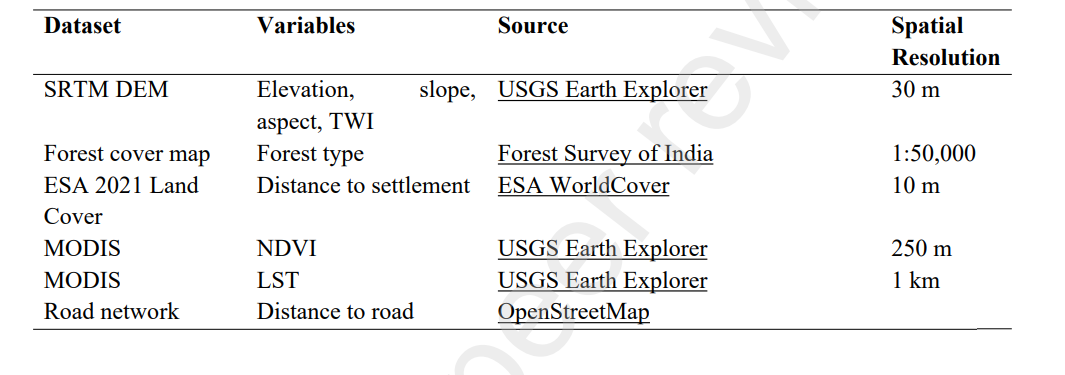

1. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from shapely.geometry import Point
from tqdm import tqdm

2. Montage Google Drive


In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


3. Chemins des fichiers


In [3]:
csv_path    = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire.csv"
raster_path ="/content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/viz.be_slope.tif"
output_csv  = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_and_slope.csv"
border_file = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/pt/pt.shp"

4. Chargement des données


In [4]:
df = pd.read_csv(csv_path)
print(df.head())

    latitude  longitude  landcover  in_fire  dist_fire_km
0  36.987823  -7.963676        210        0     17.197693
1  36.994129  -8.952213        110        0     23.004464
2  36.996850  -7.974890        210        0     16.054264
3  37.003139  -8.952309        210        0     22.375234
4  37.003216  -8.941076        210        0     21.596848


5. Création de la grille 1km x 1km


In [5]:
geometry = [Point(xy) for xy in zip(df.longitude, df.latitude)]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")
gdf = gdf.to_crs(epsg=3763)
gdf['geometry'] = gdf.geometry.buffer(500, cap_style=3)

6. Extraction de la pente moyenne par zone


In [6]:
slope_means = []

with rasterio.open(raster_path) as src:
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    nodata = src.nodata if src.nodata is not None else -9999

    for geom in tqdm(gdf.geometry, desc="Extraction"):
        try:
            out_image, _ = mask(src, [geom], crop=True)
            data = out_image[0].astype('float32')
            data[data == nodata] = np.nan
            slope_means.append(np.nanmean(data))
        except Exception:
            slope_means.append(np.nan)

Extraction: 100%|██████████| 89198/89198 [03:35<00:00, 413.13it/s]


7. Sauvegarde en CSV


In [7]:
df['mean_slope'] = slope_means
df.to_csv(output_csv, index=False)

print(f"Fichier sauvegardé : {output_csv}")
print(df[['latitude', 'longitude', 'mean_slope']].head())

Fichier sauvegardé : /content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_and_slope.csv
    latitude  longitude  mean_slope
0  36.987823  -7.963676    0.571321
1  36.994129  -8.952213    2.499209
2  36.996850  -7.974890    1.402498
3  37.003139  -8.952309    2.263847
4  37.003216  -8.941076    2.697602


8. Classification en 6 classes de pente


In [8]:
bins      = [-1, 3, 5, 10, 15, 35, 9999]
label_ids = [1, 2, 3, 4, 5, 6]

df['slope_class'] = pd.cut(df['mean_slope'], bins=bins, labels=label_ids)
df['slope_class'] = df['slope_class'].cat.add_categories([0])
df['slope_class'] = df['slope_class'].fillna(0).astype(int)

9. Visualisation cartographique


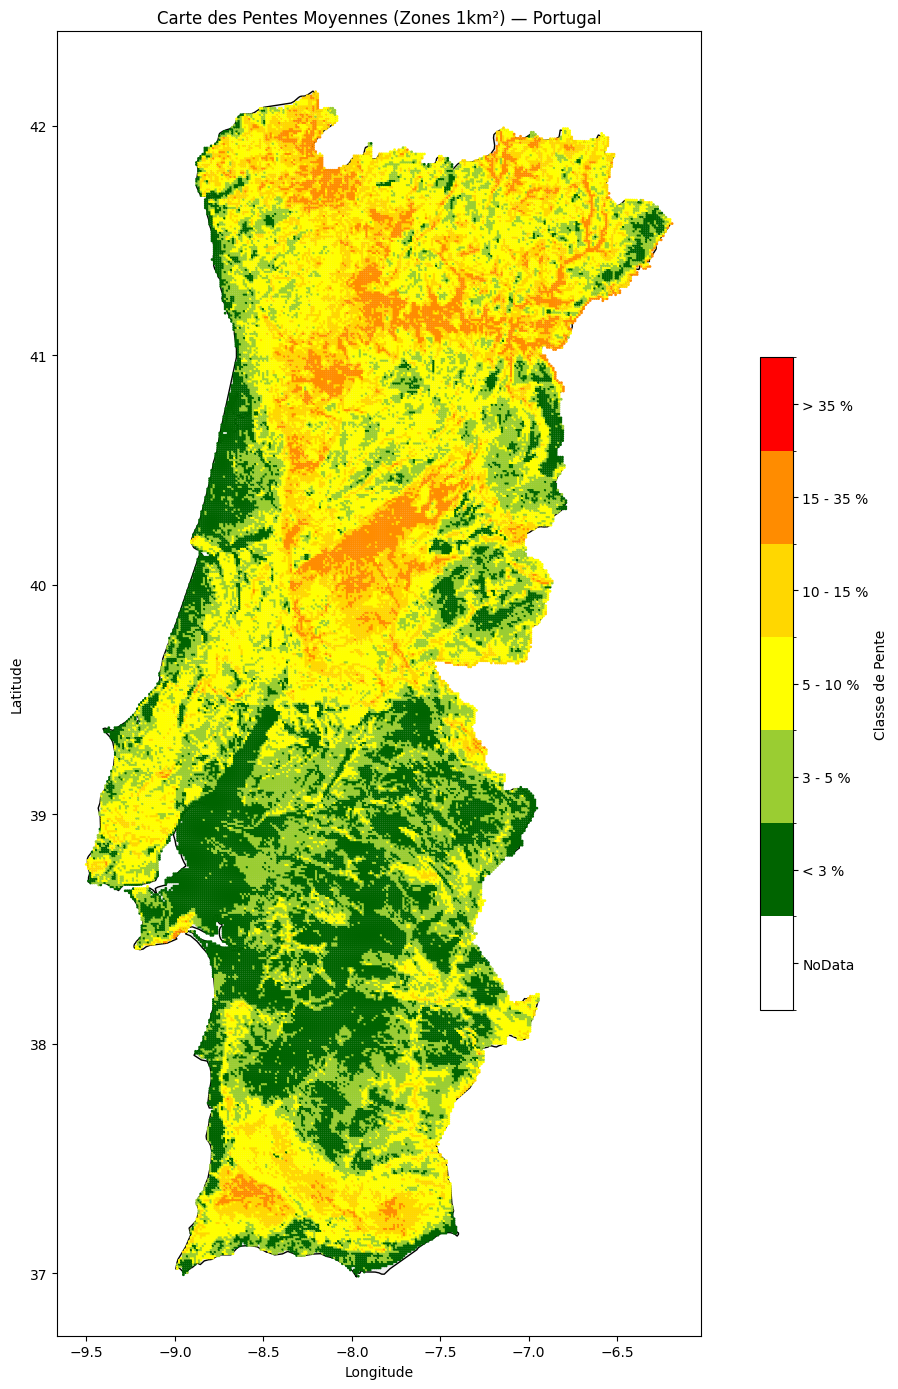

In [9]:
labels = ['NoData', '< 3 %', '3 - 5 %', '5 - 10 %', '10 - 15 %', '15 - 35 %', '> 35 %']
colors = ['#FFFFFF', '#006400', '#9ACD32', '#FFFF00', '#FFD700', '#FF8C00', '#FF0000']

cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 7.5, 1), cmap.N)

gdf_plot    = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
pt_boundary = gpd.read_file(border_file).to_crs(gdf_plot.crs)

fig, ax = plt.subplots(figsize=(12, 14))

pt_boundary.plot(ax=ax, color='#f0f0f0', edgecolor='black', linewidth=1, zorder=1)

scatter = ax.scatter(
    gdf_plot.geometry.x,
    gdf_plot.geometry.y,
    c=gdf_plot['slope_class'],
    cmap=cmap,
    norm=norm,
    s=1,
    zorder=2
)

cbar = plt.colorbar(scatter, ax=ax, ticks=np.arange(0, 7), shrink=0.5)
cbar.ax.set_yticklabels(labels)
cbar.set_label('Classe de Pente')

plt.title("Carte des Pentes Moyennes (Zones 1km²) — Portugal")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()